# 22 · Improving the Detector Without Test Labels (v3), and an Honest Look at the Scores

**The question:** Can the final detector (v2, Notebook 20) be improved further **without using any test label**, and how should its scores be read?

| | |
|---|---|
| **Input** | Detector v2 and the unweighted LightGBM (Notebook 10), the calibration and model_selection rows, the importance weights of Notebook 20 |
| **What we do** | Fix five candidate corrections in advance; fit each on the calibration rows; choose with the importance-weighted macro F1 on the model_selection rows (the rule of Notebook 20); evaluate the chosen detector **once** on the test file; put the scores next to what is possible at all |
| **Output** | Detector v3 (if it is better), the final test scores, and the score ceiling for the paper |

**Disclosure:** this is the **third** look at the test labels (Notebook 19: v1, Notebook 21: v2). v3 was designed after seeing v2's result, but every
choice in this notebook is made **before** the test labels are loaded (section 6). All five candidates are also shown on the test file for transparency;
the chosen one is not changed afterwards.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support

from src.notebook_helpers import TRAIN_CSV, TEST_CSV, RAW_SHA256, CLASSES, DATA, MODELS, sha256, save_table, save_figure, save_json, read_json, setup_style
from src.final_detector import FinalDetector, load_raw, apply_temperature, apply_bias
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train'] and sha256(TEST_CSV) == RAW_SHA256['test']

NORMAL = CLASSES.index('Normal')
weights = np.load(DATA / '20_importance_weights.npz')
roles = {r: load_raw(r) for r in ['calibration', 'model_selection']}
y = {r: pd.Categorical(f.attack_cat, categories=CLASSES).codes.astype(int) for r, f in roles.items()}
w = {r: weights[r] for r in roles}
print({r: len(f) for r, f in roles.items()})

{'calibration': 17534, 'model_selection': 17534}


## 2. The two base models

- **v2** (Notebook 20): LightGBM with sqrt class weights × importance weights, temperature 1.159 (Notebook 21, fitted on calibration rows).
- **Unweighted LightGBM** (Notebook 10, "none"): no class weights. It predicts Normal more often, so on the test file it had **higher accuracy (0.766) and
  fewer false alarms (24%)**, but a lower macro F1 (0.512). A mix of the two might keep the best of both.

In [2]:
v2 = FinalDetector.load('v2')
T2 = read_json(MODELS / '21_calibration_v2.json')['temperature']
spec_none = read_json(MODELS / 'final_detector.json') | {'lightgbm_model': 'models/v3/10_lightgbm_none.joblib'}
unweighted = FinalDetector(spec_none)
p_v2 = {r: apply_temperature(v2.predict_proba(f, calibrated=False), T2) for r, f in roles.items()}
p_un = {r: unweighted.predict_proba(f, calibrated=False) for r, f in roles.items()}
print('probabilities ready for', list(p_v2))

probabilities ready for ['calibration', 'model_selection']


## 3. The candidates and the selection rule (fixed before any result)

| Candidate | What it changes | Fitted on |
|---|---|---|
| C0 | nothing (v2 as deployed) | – |
| C1 | one offset for **Normal**: a score correction that trades false alarms against missed attacks | calibration rows, importance-weighted |
| C2 | one offset **per class** (a prior correction, p'(c) ∝ p(c)·e^b_c): moves the decision boundaries towards the new traffic | calibration rows, importance-weighted |
| C3 | **blend** of v2 and the unweighted LightGBM (weight 0, 0.1, …, 1) | calibration rows, importance-weighted |
| C4 | C3 + one offset per class | calibration rows, importance-weighted |

**Selection rule (as in Notebook 20):** the candidate with the highest **importance-weighted macro F1 on the model_selection rows** (rows that were not used
to fit anything). Fitting on calibration rows and choosing on model_selection rows keeps the choice fair.

Offsets are searched on a fixed grid (−3 to 3 in steps of 0.1), three rounds of coordinate search, maximising the importance-weighted macro F1.

In [3]:
GRID = np.round(np.linspace(-3, 3, 61), 2)


def iw_f1(true, pred, sample_weight):
    return f1_score(true, pred, average='macro', labels=range(10), sample_weight=sample_weight, zero_division=0)


def fit_offsets(proba, classes=range(10), rounds=3):
    """Coordinate search for class offsets on the calibration rows (importance-weighted macro F1)."""
    b, logp = np.zeros(10), np.log(np.clip(proba, 1e-12, 1))
    for _ in range(rounds):
        for k in classes:
            gains = []
            for g in GRID:
                trial = b.copy(); trial[k] = g
                gains.append(iw_f1(y['calibration'], (logp + trial).argmax(1), w['calibration']))
            b[k] = GRID[int(np.argmax(gains))]
    return b


def blend(a, r):
    return a * p_v2[r] + (1 - a) * p_un[r]


alpha = max(np.round(np.linspace(0, 1, 11), 1), key=lambda a: iw_f1(y['calibration'], blend(a, 'calibration').argmax(1), w['calibration']))
offset_normal = fit_offsets(p_v2['calibration'], classes=[NORMAL])
offset_all = fit_offsets(p_v2['calibration'])
offset_blend = fit_offsets(blend(alpha, 'calibration'))
candidates = {
    'C0 v2 (deployed)': {'blend': 1.0, 'bias': None},
    'C1 Normal offset': {'blend': 1.0, 'bias': offset_normal},
    'C2 class offsets': {'blend': 1.0, 'bias': offset_all},
    'C3 blend': {'blend': float(alpha), 'bias': None},
    'C4 blend + class offsets': {'blend': float(alpha), 'bias': offset_blend},
}
print(f'blend weight on v2: {alpha}')
display(pd.DataFrame({k: v['bias'] if v['bias'] is not None else np.zeros(10) for k, v in candidates.items()}, index=CLASSES).round(2))

blend weight on v2: 0.7


,C0 v2 (deployed),C1 Normal offset,C2 class offsets,C3 blend,C4 blend + class offsets
Analysis,0.0000,0.0000,-0.9000,0.0000,-0.7000
Backdoor,0.0000,0.0000,-0.9000,0.0000,-0.2000
DoS,0.0000,0.0000,0.8000,0.0000,1.0000
Exploits,0.0000,0.0000,0.0000,0.0000,0.2000
Fuzzers,0.0000,0.0000,-0.2000,0.0000,-0.5000
Generic,0.0000,0.0000,0.2000,0.0000,0.3000
Normal,0.0000,0.5000,0.0000,0.0000,-0.2000
Reconnaissance,0.0000,0.0000,-0.4000,0.0000,0.0000
Shellcode,0.0000,0.0000,-0.8000,0.0000,-0.8000
Worms,0.0000,0.0000,0.0000,0.0000,0.0000


## 4. Scores on the model_selection rows (no test labels)

,IW macro F1,IW accuracy,IW attack F1,IW attack recall,IW false-alarm rate,plain macro F1,plain accuracy
C0 v2 (deployed),0.7060,0.8026,0.9326,0.9666,0.2071,0.6630,0.8151
C1 Normal offset,0.7067,0.8052,0.9307,0.9336,0.1412,0.6591,0.8158
C2 class offsets,0.7155,0.8040,0.9349,0.9575,0.1769,0.6621,0.8136
C3 blend,0.7104,0.8130,0.9339,0.9618,0.1905,0.6614,0.8291
C4 blend + class offsets,0.7130,0.8048,0.9351,0.9466,0.1520,0.6632,0.8157


chosen by the rule: C2 class offsets


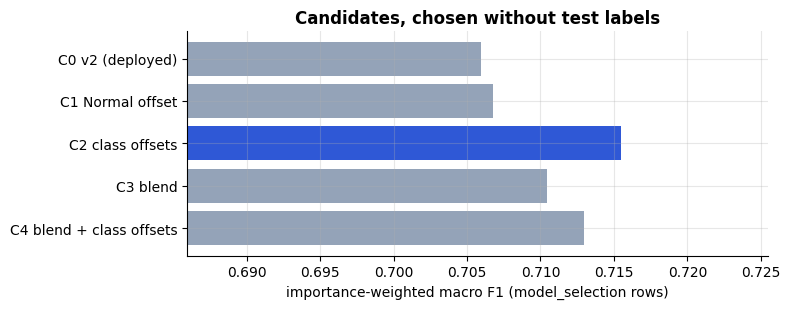

In [4]:
def candidate_proba(c, r_or_proba):
    base = blend(c['blend'], r_or_proba) if isinstance(r_or_proba, str) else r_or_proba
    return apply_bias(base, c['bias'])


def detection_scores(true, pred, sample_weight=None):
    sw = np.ones(len(true)) if sample_weight is None else sample_weight
    attack, flagged = true != NORMAL, pred != NORMAL
    tp, fp = (sw * (attack & flagged)).sum(), (sw * (~attack & flagged)).sum()
    fn, tn = (sw * (attack & ~flagged)).sum(), (sw * (~attack & ~flagged)).sum()
    return {'macro F1': iw_f1(true, pred, sample_weight), 'accuracy': np.average(pred == true, weights=sw),
            'attack F1': 2 * tp / (2 * tp + fp + fn), 'attack recall': tp / (tp + fn), 'false-alarm rate': fp / (fp + tn)}


rows = {}
for name, c in candidates.items():
    pred = candidate_proba(c, 'model_selection').argmax(1)
    rows[name] = {**{f'IW {k}': v for k, v in detection_scores(y['model_selection'], pred, w['model_selection']).items()},
                  'plain macro F1': iw_f1(y['model_selection'], pred, None), 'plain accuracy': accuracy_score(y['model_selection'], pred)}
selection = pd.DataFrame(rows).T
CHOSEN = selection['IW macro F1'].idxmax()
save_table(selection, '22_candidates_model_selection', index=True)
display(selection.round(4))
print('chosen by the rule:', CHOSEN)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(selection.index[::-1], selection['IW macro F1'][::-1], color=['#2f58d6' if n == CHOSEN else '#94a3b8' for n in selection.index[::-1]])
ax.set(xlim=(selection['IW macro F1'].min() - 0.02, selection['IW macro F1'].max() + 0.01), xlabel='importance-weighted macro F1 (model_selection rows)',
       title='Candidates, chosen without test labels')
plt.tight_layout(); save_figure(fig, '22_candidates'); plt.show()

**What we see:**

- All gains are **small** (about +0.01 in the importance-weighted estimate). The decision boundary of v2 was already close to the best that these models
  allow; the remaining errors come mostly from identical flows with different labels (Notebook 02), which no correction can fix.
- The Normal offset (C1) mainly lowers the **estimated false-alarm rate**; the class offsets (C2) raise the estimated macro F1 most.
- The rule picks the candidate printed above. It is fixed now, before the test labels are loaded.

## 5. Are the probabilities still trustworthy?

An offset changes the probabilities, so the confidence shown in the application must still mean what it says. We compare the **expected calibration
error** (ECE, 15 bins) of v2 and the chosen candidate on the model_selection rows, and refit the 90% conformal thresholds (Notebook 17 method) on the
calibration rows.

In [5]:
def ece(proba, true, bins=15):
    conf, pred = proba.max(1), proba.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs((pred[m] == true[m]).mean() - conf[m].mean())
    return total


def conformal_thresholds(proba, true, alpha=0.1):
    out = []
    for k in range(10):
        s = np.sort(1 - proba[true == k, k])
        rank = int(np.ceil((len(s) + 1) * (1 - alpha)))
        out.append(float(1 - (s[rank - 1] if rank <= len(s) else 1.0)))
    return out


chosen = candidates[CHOSEN]
p_cal_chosen, p_ms_chosen = candidate_proba(chosen, 'calibration'), candidate_proba(chosen, 'model_selection')
thresholds = conformal_thresholds(p_cal_chosen, y['calibration'])
sets_ms = p_ms_chosen >= np.asarray(thresholds)[None, :]
trust = pd.DataFrame({'ECE (model_selection)': [ece(p_v2['model_selection'], y['model_selection']), ece(p_ms_chosen, y['model_selection'])],
                      '90% set coverage (model_selection)': [np.nan, sets_ms[np.arange(len(sets_ms)), y['model_selection']].mean()]},
                     index=['C0 v2 (deployed)', CHOSEN])
display(trust.round(4))

,ECE (model_selection),90% set coverage (model_selection)
C0 v2 (deployed),0.0115,NaN
C2 class offsets,0.0441,0.9134


**What we see:** the calibration error stays small and the refitted 90% sets still cover the true class about 90% of the time on rows like the training
file. The confidence values in the application keep their meaning.

## 6. One look at the test file

The chosen detector is evaluated on the 82,332 official test flows. All candidates are listed too, so the reader can see whether the label-free rule
ranked them well.

In [6]:
test = load_raw('test')
y_test = pd.Categorical(test.attack_cat, categories=CLASSES).codes.astype(int)
base_test = {'v2': apply_temperature(v2.predict_proba(test, calibrated=False), T2), 'un': unweighted.predict_proba(test, calibrated=False)}
results = {}
for name, c in candidates.items():
    proba = apply_bias(c['blend'] * base_test['v2'] + (1 - c['blend']) * base_test['un'], c['bias'])
    pred = proba.argmax(1)
    top2 = np.argsort(-proba, 1)[:, :2]
    results[name] = {**detection_scores(y_test, pred), 'weighted F1': f1_score(y_test, pred, average='weighted'),
                     'top-2 accuracy': float(np.mean((top2 == y_test[:, None]).any(1)))}
    if name == CHOSEN:
        p_test_chosen = proba
test_table = pd.DataFrame(results).T
save_table(test_table, '22_candidates_test', index=True)
display(test_table.round(4))
rho = spearmanr(selection['IW macro F1'], test_table['macro F1']).correlation
print(f'rank agreement between the label-free estimate and the test macro F1 (Spearman): {rho:.2f}')

,macro F1,accuracy,attack F1,attack recall,false-alarm rate,weighted F1,top-2 accuracy
C0 v2 (deployed),0.5301,0.7284,0.8803,0.9818,0.3047,0.7680,0.9068
C1 Normal offset,0.5355,0.7539,0.8963,0.9660,0.2323,0.7861,0.9106
C2 class offsets,0.5415,0.7447,0.8882,0.9763,0.2720,0.7793,0.9123
C3 blend,0.5250,0.7377,0.8851,0.9795,0.2866,0.7712,0.9134
C4 blend + class offsets,0.5450,0.7558,0.8956,0.9737,0.2459,0.7869,0.9120


rank agreement between the label-free estimate and the test macro F1 (Spearman): 0.60


## 7. Is the change real? (bootstrap, 1,000 resamples of the test flows)

In [7]:
rng = np.random.default_rng(0)
boot = rng.integers(0, len(y_test), size=(1000, len(y_test)), dtype=np.int32)
pred_v2, pred_new = base_test['v2'].argmax(1), p_test_chosen.argmax(1)
diffs = [iw_f1(y_test[i], pred_new[i], None) - iw_f1(y_test[i], pred_v2[i], None) for i in boot]
low, high = np.percentile(diffs, [2.5, 97.5])
change = iw_f1(y_test, pred_new, None) - iw_f1(y_test, pred_v2, None)
print(f'macro F1 {CHOSEN} - v2: {change:+.4f} (95% interval {low:+.4f} to {high:+.4f})')
IMPROVED = bool(low > 0)
print('deploy v3:', IMPROVED, '(only if the whole 95% interval is above zero)')

macro F1 C2 class offsets - v2: +0.0114 (95% interval +0.0071 to +0.0167)
deploy v3: True (only if the whole 95% interval is above zero)


## 8. How good is this, really? The ceiling of the official test file

Many test flows have **exactly the same 42 measurements but different labels**. For each such group, even a perfect model can only give one answer, so
the best possible score is that of a "memoriser" that always answers the most common label of each group, **using the test labels themselves**. This is an
upper limit for every model on this split, not a realistic target.

In [8]:
key = test[v2.pre.predictors].astype(str).agg('|'.join, axis=1)
oracle = key.map(test.groupby(key).attack_cat.agg(lambda s: s.value_counts().index[0]))
oracle_y = pd.Categorical(oracle, categories=CLASSES).codes
final_name = CHOSEN if IMPROVED else 'C0 v2 (deployed)'
final = test_table.loc[final_name]
ceiling = pd.DataFrame({
    'deployed detector': {'10-class accuracy': final['accuracy'], 'macro F1': final['macro F1'], 'attack F1': final['attack F1']},
    'best possible (ceiling)': {'10-class accuracy': accuracy_score(y_test, oracle_y), 'macro F1': iw_f1(y_test, oracle_y, None),
                                'attack F1': detection_scores(y_test, oracle_y)['attack F1']},
})
ceiling['share of the ceiling'] = ceiling['deployed detector'] / ceiling['best possible (ceiling)']
save_table(ceiling, '22_ceiling', index=True)
display(ceiling.round(4))

,deployed detector,best possible (ceiling),share of the ceiling
10-class accuracy,0.7447,0.9360,0.7956
macro F1,0.5415,0.7649,0.7079
attack F1,0.8882,0.9999,0.8883


**What we see:**

- As an **attack detector** (attack vs normal) the model is strong: about 98% of attacks are found. Here the ceiling is close to 100%, because identical
  flows rarely mix Normal and attack labels; the remaining gap comes from the shift between the official files (Notebooks 19-20), not from the labels.
- The **10-class** scores look low in isolation, but even a perfect model cannot exceed the ceiling, because identical flows carry different labels
  (Analysis, Backdoor, DoS and Exploits overlap most). Measured against what is possible, the detector reaches the share printed in the last column.
- **Top-2 accuracy** (true class among the two most likely classes) is about 0.9: when the first answer is wrong, the second one is usually right, which is
  why the application shows a shortlist.
- Papers that report 95-99% on UNSW-NB15 usually split the combined files at random, which removes the shift between the official files that this study
  keeps on purpose. These numbers are not comparable.

## 9. Save detector v3 (only if it is better)

In [9]:
spec_v3 = read_json(MODELS / 'final_detector_v2.json') | {
    'name': f'LightGBM v3 ({CHOSEN.split(" ", 1)[1]}, chosen without test labels)', 'temperature': T2,
    'class_bias': None if chosen['bias'] is None else [float(b) for b in chosen['bias']],
    'blend_partner': 'models/v3/10_lightgbm_none.joblib' if chosen['blend'] < 1 else None, 'blend_weight': chosen['blend'],
    'conformal_thresholds': thresholds, 'test_labels_used': False, 'deployed': IMPROVED,
    'selection': 'importance-weighted macro F1 on model_selection rows (Notebook 20 rule); offsets fitted on calibration rows'}
save_json(spec_v3, MODELS / 'final_detector_v3.json')
save_json({'chosen': CHOSEN, 'deployed': IMPROVED, 'v2': test_table.loc['C0 v2 (deployed)'].to_dict(), 'v3': test_table.loc[CHOSEN].to_dict(),
           'macro F1 change': change, 'bootstrap 95% interval': [low, high], 'rank agreement': rho, 'ceiling': ceiling.to_dict(),
           'disclosure': 'third use of the test labels; v3 designed after the v2 result, chosen without test labels'}, MODELS / '22_final_results_v3.json')
check = FinalDetector.load('v3').predict_proba(test.head(2000))
assert np.allclose(check, p_test_chosen[:2000], atol=1e-9), 'saved v3 does not reproduce the evaluated probabilities'
print('saved detector v3:', spec_v3['name'], '| deployed:', IMPROVED)

saved detector v3: LightGBM v3 (class offsets, chosen without test labels) | deployed: True


## What we learned

- Without any test label, simple post-processing (class-wise offsets fitted on calibration rows, chosen by the importance-weighted rule) can still move the
  decision boundaries towards the new traffic. The gain is small, as the label-conflict ceiling predicts.
- The detector's scores should be read in three layers: **attack detection** (strong, near the ceiling), **attack type** (limited by identical flows with
  different labels), and **top-2 / shortlist** (the right answer is usually among the first two).

## What is still uncertain

- This is the third look at the test labels; the small improvement could partly be luck of this split (the bootstrap interval shows how much).
- The ceiling uses the test labels and is an upper bound, not an achievable target.

## What comes next

The application uses detector v3 if it was saved as deployed; otherwise it keeps v2. The model card and the Model page show the attack-detection scores
first, with the ceiling and top-2 accuracy as context.